# EDA · Encuesta ASP 2022 (Bogotá)

Proyecto integrador: segmentación predictiva de la vulnerabilidad en el acceso a salud de la población ASP en Bogotá

Integrantes: Stefany Pulido Valero, Daniela Sofía López Rivas y Lezly Juliana Nossa López

En este notebook exploramos los datos de la encuesta antes de mirar los grupos que salieron del clustering. Cada paso tiene una explicación corta arriba y el código abajo. Se corre en orden, de arriba hacia abajo, con Shift + Enter.

## Paso 0 · Cargar los datos

Primero importamos las librerías y leemos el archivo CSV. Antes de analizar nada hay que confirmar que los datos cargaron completos: tienen que salir 3003 filas y 50 columnas.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import os

os.makedirs("figuras", exist_ok=True)   # carpeta donde se guardarán las gráficas

df = pd.read_csv("asp_2022_variables_limpio.csv")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (3003, 50)


,id_persona,factor_expansion,localidad,edad,sexo_nacimiento,orientacion_sexual,identidad_genero,estado_civil,autoreconocimiento_etnico,pais_nacimiento,...,vacuna_vph,citologia_ultimo_anio,discriminacion_general,discriminacion_personal_salud,amenazas_recibidas,amenaza_personal_salud,forzada_relaciones_sexuales,forzada_por_personal_salud,denuncio_hecho,violencia_fuerza_publica
0,1501001,1.428571,Antonio Nariño,19,Mujer,Bisexual,Femenina,Soltero(a),Ninguno,Colombia,...,Sí,Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
1,1501002,1.428571,Antonio Nariño,26,Hombre,Heterosexual,Femenina,Soltero(a),Ninguno,Venezuela,...,No aplica (no se hizo la pregunta),Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
2,1501003,1.428571,Antonio Nariño,21,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,Venezuela,...,No,Sí,No,No aplica (no se hizo la pregunta),Sí,No,Sí,No,No,Sí
3,1501004,1.428571,Antonio Nariño,20,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,Colombia,...,Sí,Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
4,1501005,1.428571,Antonio Nariño,20,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,Venezuela,...,No,No,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No


## Paso 1 · Tarea 15: estadísticas descriptivas de las variables numéricas

Hacemos un resumen de cada variable numérica: media, mediana, mínimo y máximo. Agregamos dos columnas:

- *media_ponderada*: cada persona cuenta según a cuántas representa (`factor_expansion`). Así la cifra habla de la población y no solo de las personas encuestadas.
- *coef_variacion_%*: dice qué tan dispersa es la variable. Si es alto, las personas se parecen poco entre sí.

In [41]:
numericas = ["edad", "personas_hogar", "dependientes_economicos", "autopercepcion_nivel_economico",
             "satisfaccion_actividad", "horas_semana_asp", "edad_inicio_asp"]

tabla = df[numericas].describe().T.round(2)

# media ponderada = cada persona cuenta según cuántas personas representa
peso = df["factor_expansion"]
tabla["media_ponderada"] = [round((df[c] * peso).sum() / peso.sum(), 2) for c in numericas]

# coeficiente de variación: qué tan dispersa es la variable respecto a su media
tabla["coef_variacion_%"] = (df[numericas].std() / df[numericas].mean() * 100).round(1)
tabla

,count,mean,std,min,25%,50%,75%,max,media_ponderada,coef_variacion_%
edad,3003.0,31.76,10.75,18.0,24.0,29.0,37.0,77.0,31.07,33.9
personas_hogar,3003.0,2.45,1.58,1.0,1.0,2.0,3.0,9.0,2.50,64.4
dependientes_economicos,3003.0,2.16,1.71,0.0,1.0,2.0,3.0,7.0,2.28,79.0
autopercepcion_nivel_economico,3003.0,3.44,1.80,1.0,2.0,3.0,5.0,10.0,3.54,52.1
satisfaccion_actividad,3003.0,3.88,2.53,1.0,2.0,4.0,5.0,10.0,3.88,65.3
horas_semana_asp,3003.0,47.24,20.80,1.0,32.0,48.0,60.0,84.0,47.15,44.0
edad_inicio_asp,3003.0,22.28,7.05,10.0,18.0,20.0,25.0,65.0,22.47,31.6


## Paso 2 · Tarea 16: tablas de frecuencia de las variables de categorías

Contamos cuántas personas hay en cada respuesta, primero en la muestra y después ponderando con `factor_expansion`.

Hay dos columnas de porcentaje porque la encuesta no tomó el mismo número de personas en todos los lugares. Por ejemplo, Los Mártires pasa de 43,6 % en la muestra a 37,1 % ponderado. El que representa a la población es el ponderado.

In [42]:
def frecuencia(col):
    t = df.groupby(col)["factor_expansion"].agg(["size", "sum"])
    t.columns = ["personas_muestra", "poblacion_estimada"]
    t["%_muestra"] = t["personas_muestra"] / t["personas_muestra"].sum() * 100
    t["%_ponderado"] = t["poblacion_estimada"] / t["poblacion_estimada"].sum() * 100
    return t.sort_values("%_ponderado", ascending=False).round(1)

for col in ["nivel_educativo", "pais_nacimiento", "tiempo_viviendo_bogota",
            "ingresos_suficientes_gastos", "afiliado_seg_social_salud"]:
    print("\n=====", col)
    print(frecuencia(col))

print("\n===== localidad")
frecuencia("localidad")


===== nivel_educativo
                   personas_muestra  poblacion_estimada  %_muestra  \
nivel_educativo                                                      
Media                          1122              1647.5       37.4   
Básica secundaria               824              1225.4       27.4   
Básica primaria                 386               515.1       12.9   
Universitario                   272               437.8        9.1   
Técnico                         213               324.7        7.1   
Ninguno                         114               150.7        3.8   
Tecnológico                      58                91.6        1.9   
Preescolar                       10                11.4        0.3   
Especialización                   3                 4.4        0.1   
Doctorado                         1                 1.1        0.0   

                   %_ponderado  
nivel_educativo                 
Media                     37.4  
Básica secundaria         27.8  
Bási

,personas_muestra,poblacion_estimada,%_muestra,%_ponderado
localidad,,,,
Los Mártires,1308,1636.0,43.6,37.1
Kennedy,422,740.0,14.1,16.8
Barrios Unidos,274,383.0,9.1,8.7
Santa Fe,306,383.0,10.2,8.7
Engativá,82,223.0,2.7,5.1
Chapinero,118,185.7,3.9,4.2
Tunjuelito,98,157.0,3.3,3.6
Usaquén,52,93.0,1.7,2.1
Ciudad Bolívar,40,92.0,1.3,2.1


## Paso 3 · Tarea 17: distribución de la edad

Dibujamos un histograma (cuántas personas hay en cada rango de edad) y un boxplot (mediana, cuartiles y valores extremos).

La mayoría de la población es joven y hay pocas personas mayores que alargan la cola derecha (asimetría de 1,15). Por eso la mediana (29) queda por debajo de la media (31,8).

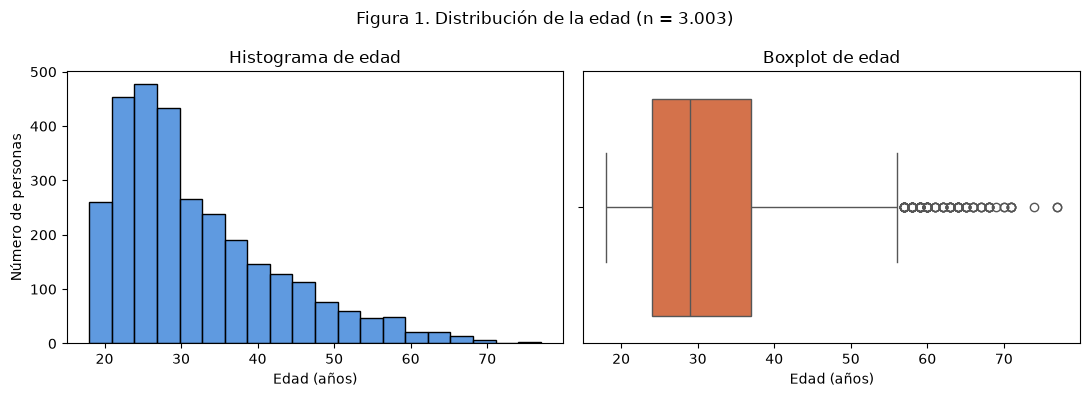

Cuartiles: [24.0, 29.0, 37.0]
Asimetría: 1.15


In [43]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["edad"], bins=20, ax=ax[0], color="#2a78d6")
ax[0].set_title("Histograma de edad")
ax[0].set_xlabel("Edad (años)"); ax[0].set_ylabel("Número de personas")
sns.boxplot(x=df["edad"], ax=ax[1], color="#eb6834")
ax[1].set_title("Boxplot de edad"); ax[1].set_xlabel("Edad (años)")
fig.suptitle("Figura 1. Distribución de la edad (n = 3.003)")
plt.tight_layout()
plt.savefig("figuras/figura1_edad.png", dpi=300)
plt.show()

print("Cuartiles:", df["edad"].quantile([0.25, 0.5, 0.75]).tolist())
print("Asimetría:", round(df["edad"].skew(), 2))

## Paso 4 · Tarea 18: escolaridad e ingresos

Agrupamos los niveles educativos y miramos, en porcentajes ponderados, hasta dónde estudió la gente y si los ingresos le alcanzan para los gastos.

El 80,5 % llegó como máximo a educación media, y el 68,9 % dice que sus ingresos no alcanzan.

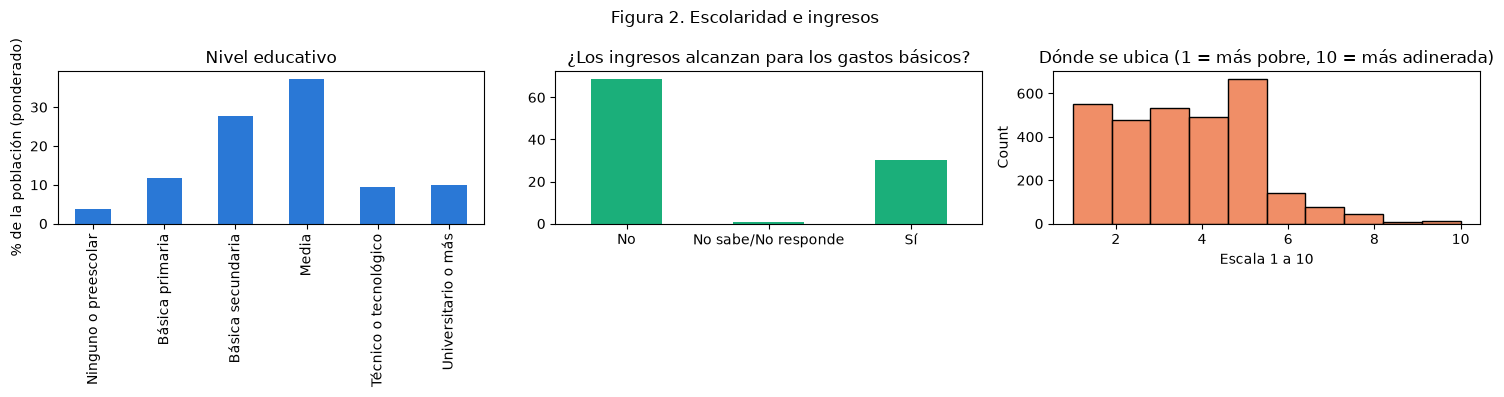

educacion
Ninguno o preescolar      3.7
Básica primaria          11.7
Básica secundaria        27.8
Media                    37.4
Técnico o tecnológico     9.4
Universitario o más      10.1
Name: factor_expansion, dtype: float64


In [44]:
# agrupamos niveles con muy pocas personas para que la gráfica sea legible
grupo_edu = {"Ninguno": "Ninguno o preescolar", "Preescolar": "Ninguno o preescolar",
             "Básica primaria": "Básica primaria", "Básica secundaria": "Básica secundaria",
             "Media": "Media", "Técnico": "Técnico o tecnológico", "Tecnológico": "Técnico o tecnológico",
             "Universitario": "Universitario o más", "Especialización": "Universitario o más",
             "Doctorado": "Universitario o más"}
orden_edu = ["Ninguno o preescolar", "Básica primaria", "Básica secundaria", "Media",
             "Técnico o tecnológico", "Universitario o más"]
df["educacion"] = df["nivel_educativo"].map(grupo_edu)

edu = df.groupby("educacion")["factor_expansion"].sum().reindex(orden_edu)
edu = edu / edu.sum() * 100

ing = df.groupby("ingresos_suficientes_gastos")["factor_expansion"].sum()
ing = ing / ing.sum() * 100

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
edu.plot.bar(ax=ax[0], color="#2a78d6"); ax[0].set_title("Nivel educativo"); ax[0].set_xlabel("")
ax[0].set_ylabel("% de la población (ponderado)")
ing.plot.bar(ax=ax[1], color="#1baf7a"); ax[1].set_title("¿Los ingresos alcanzan para los gastos básicos?")
ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0)
sns.histplot(df["autopercepcion_nivel_economico"], bins=10, ax=ax[2], color="#eb6834")
ax[2].set_title("Dónde se ubica (1 = más pobre, 10 = más adinerada)"); ax[2].set_xlabel("Escala 1 a 10")
fig.suptitle("Figura 2. Escolaridad e ingresos")
plt.tight_layout()
plt.savefig("figuras/figura2_escolaridad_ingresos.png", dpi=300)
plt.show()
print(edu.round(1))

## Paso 5 · Tarea 19: distribución por localidad

Vemos en qué localidades de Bogotá vive la población.

Los Mártires reúne el 37,1 % (ponderado) y Kennedy el 16,8 %. Por eso la muestra tiene tantas personas de Los Mártires.

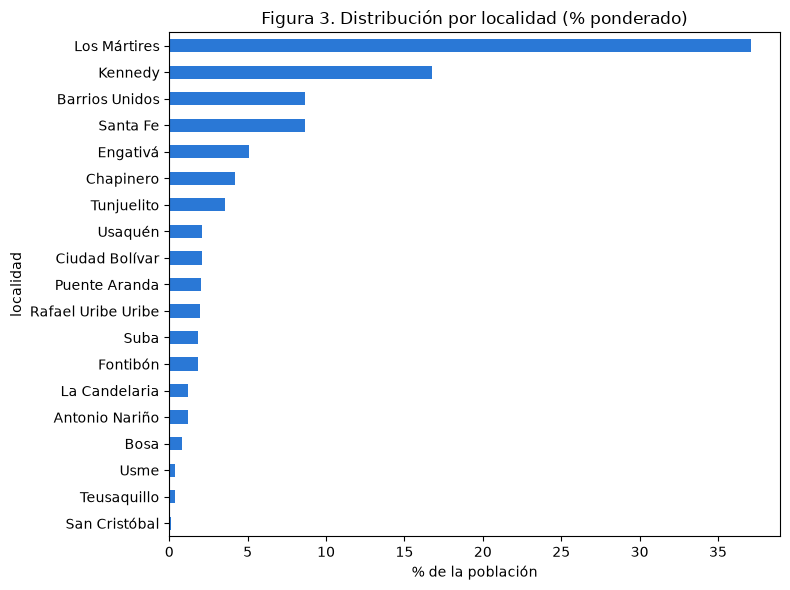

localidad
Los Mártires      37.1
Kennedy           16.8
Barrios Unidos     8.7
Santa Fe           8.7
Engativá           5.1
Name: factor_expansion, dtype: float64


In [45]:
loc = df.groupby("localidad")["factor_expansion"].sum()
loc = (loc / loc.sum() * 100).sort_values()

plt.figure(figsize=(8, 6))
loc.plot.barh(color="#2a78d6")
plt.title("Figura 3. Distribución por localidad (% ponderado)")
plt.xlabel("% de la población")
plt.tight_layout()
plt.savefig("figuras/figura3_localidad.png", dpi=300)
plt.show()
print(loc.sort_values(ascending=False).head(5).round(1))

## Paso 6 · Tarea 20: la variable objetivo, afiliación a salud

Esta es la variable que queremos entender: si la persona está afiliada a salud o no. También revisamos si hay desbalance.

Ponderado, No es 50,6 % y Sí 49,0 %. Está casi 50/50, así que no hay desbalance y no hay que corregir nada. Las 12 personas que respondieron «No sabe/No responde» las dejamos fuera de los cruces, y quedan 2.991.

                           personas_muestra  poblacion_estimada  %_muestra  \
afiliado_seg_social_salud                                                    
No                                     1492              2233.4       49.7   
Sí                                     1499              2161.8       49.9   
No sabe/No responde                      12                14.5        0.4   

                           %_ponderado  
afiliado_seg_social_salud               
No                                50.6  
Sí                                49.0  
No sabe/No responde                0.3  

Personas en la base de análisis: 2991


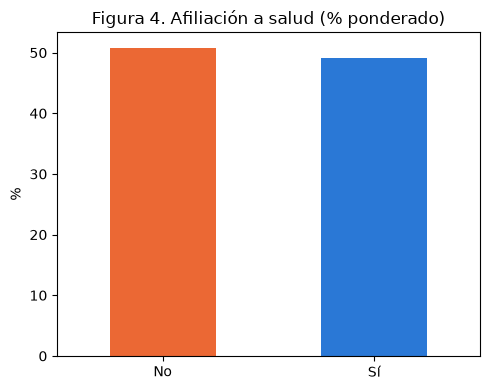

In [46]:
print(frecuencia("afiliado_seg_social_salud"))

# para los cruces dejamos fuera a las 12 personas que no sabían / no respondieron
base = df[df["afiliado_seg_social_salud"] != "No sabe/No responde"].copy()
base["no_afiliada"] = (base["afiliado_seg_social_salud"] == "No").astype(int)
print("\nPersonas en la base de análisis:", len(base))

# agrupamos el país de nacimiento para evitar categorías de 1 sola persona
base["origen"] = base["pais_nacimiento"].where(base["pais_nacimiento"].isin(["Colombia", "Venezuela"]), "Otro / NS-NR")

obj = base.groupby("afiliado_seg_social_salud")["factor_expansion"].sum()
obj = obj / obj.sum() * 100
plt.figure(figsize=(5, 4))
obj.plot.bar(color=["#eb6834", "#2a78d6"])
plt.title("Figura 4. Afiliación a salud (% ponderado)")
plt.xlabel(""); plt.ylabel("%"); plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figuras/figura4_afiliacion.png", dpi=300)
plt.show()

## Paso 7 · Tarea 21: cruces de variables clave contra la afiliación

Para cada variable calculamos qué porcentaje de cada grupo está afiliado y cuál no (ponderado), y lo graficamos en barras apiladas. Lo que más se ve:

- **País de nacimiento:** sin afiliación 21,1 % en Colombia contra 85,9 % en Venezuela. Es la diferencia más grande.
- **Tiempo en Bogotá:** con menos de 5 años, cerca del 74 % no tiene afiliación; con más de 10 años, el 19 %.
- **Ingresos:** quienes dicen que sus ingresos *sí* alcanzan tienen *menos* afiliación (58,6 % sin afiliación contra 47,3 %). Eso va al revés de lo que esperaríamos, y lo explicamos en el Paso 7B.


----- País de nacimiento
afiliado_seg_social_salud    No    Sí
origen                               
Colombia                   21.1  78.9
Otro / NS-NR               85.1  14.9
Venezuela                  85.9  14.1

----- Tiempo viviendo en Bogotá
afiliado_seg_social_salud    No    Sí
tiempo_viviendo_bogota               
Menos de 1 año             74.2  25.8
Entre 1 y 5 años           73.4  26.6
Entre 6 y 10 años          41.0  59.0
Más de 10 años             19.1  80.9

----- Nivel educativo
afiliado_seg_social_salud    No    Sí
educacion                            
Ninguno o preescolar       50.6  49.4
Básica primaria            34.9  65.1
Básica secundaria          51.9  48.1
Media                      51.9  48.1
Técnico o tecnológico      41.7  58.3
Universitario o más        70.9  29.1

----- ¿Ingresos alcanzan?
afiliado_seg_social_salud      No    Sí
ingresos_suficientes_gastos            
Sí                           58.6  41.4
No                           47.3  52.7


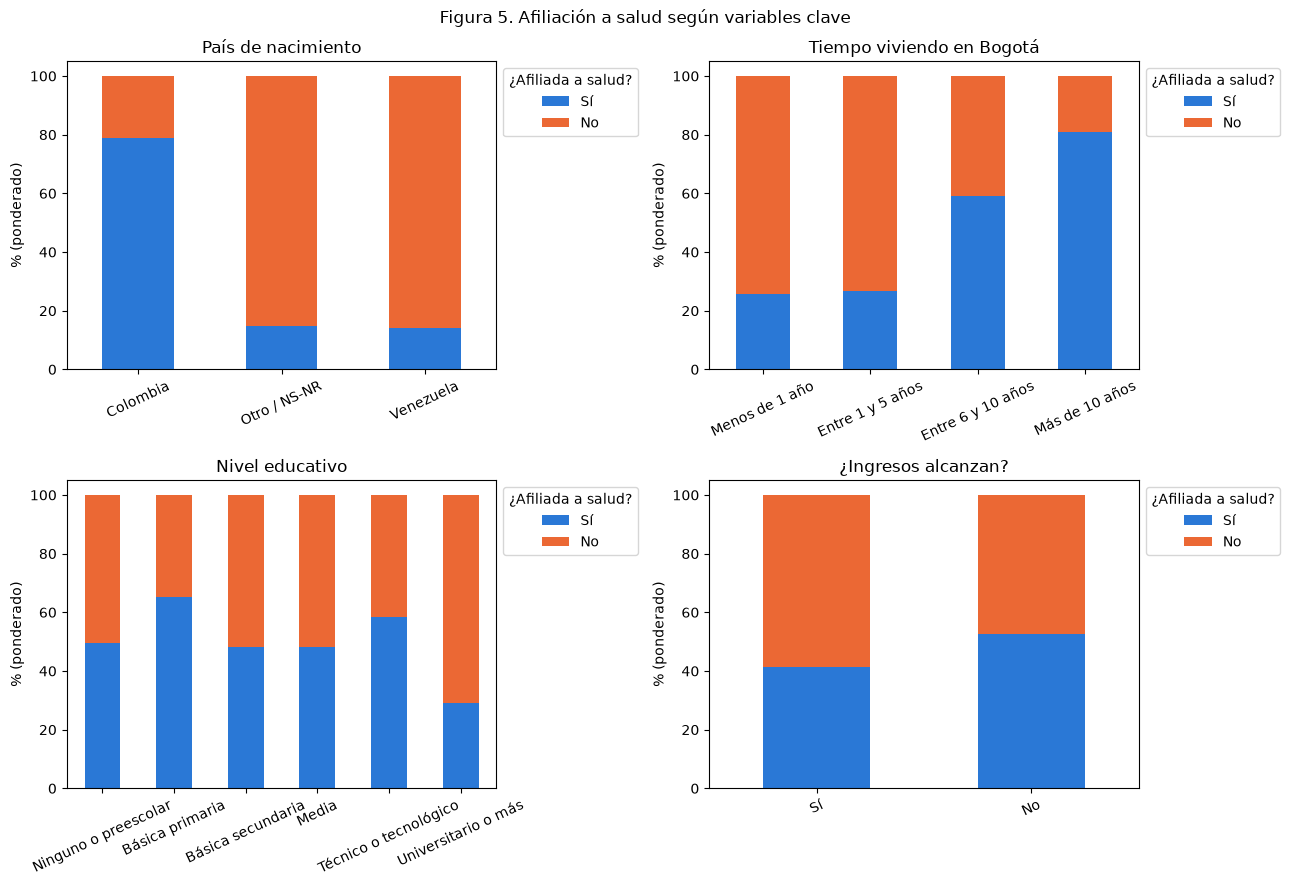

In [47]:
def cruce(col, orden=None):
    t = pd.crosstab(base[col], base["afiliado_seg_social_salud"],
                    values=base["factor_expansion"], aggfunc="sum", normalize="index") * 100
    if orden is not None:
        t = t.reindex(orden)
    return t.round(1)

base["educacion"] = base["nivel_educativo"].map(grupo_edu)
orden_tiempo = ["Menos de 1 año", "Entre 1 y 5 años", "Entre 6 y 10 años", "Más de 10 años"]

cruces = {"origen": ("País de nacimiento", None),
          "tiempo_viviendo_bogota": ("Tiempo viviendo en Bogotá", orden_tiempo),
          "educacion": ("Nivel educativo", orden_edu),
          "ingresos_suficientes_gastos": ("¿Ingresos alcanzan?", ["Sí", "No"])}

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, (col, (titulo, orden)) in zip(ax.flatten(), cruces.items()):
    t = cruce(col, orden)
    print("\n-----", titulo); print(t)
    t[["Sí", "No"]].plot.bar(stacked=True, ax=a, color=["#2a78d6", "#eb6834"])
    a.set_title(titulo); a.set_xlabel(""); a.set_ylabel("% (ponderado)")
    a.legend(title="¿Afiliada a salud?", loc="upper left", bbox_to_anchor=(1.0, 1.0)); a.tick_params(axis="x", rotation=25)
fig.suptitle("Figura 5. Afiliación a salud según variables clave")
plt.tight_layout()
plt.savefig("figuras/figura5_cruces.png", dpi=300)
plt.show()

## Paso 7B · Tarea 21 (extra): ¿el país de origen está «tapando» otras relaciones?

Repetimos el cruce de ingresos y el de educación, pero separando primero por país de origen.

Lo hacemos porque el origen se relaciona con casi todo (ingresos, tiempo en Bogotá, educación). Si no lo separamos, parece que los ingresos o la educación afectan la afiliación, cuando en realidad puede ser el origen. A eso se le llama **variable de confusión**.

Dentro de cada país las diferencias casi desaparecen (por ejemplo, en Colombia 20,9 % contra 22,0 %). Entonces lo que pesa es el origen y el tiempo en Bogotá, no los ingresos.

In [48]:
b2 = base[base["origen"].isin(["Colombia", "Venezuela"])]

# ingresos vs afiliación, separando por origen
t = pd.crosstab([b2["origen"], b2["ingresos_suficientes_gastos"]], b2["afiliado_seg_social_salud"],
                values=b2["factor_expansion"], aggfunc="sum", normalize="index") * 100
t["n_personas"] = pd.crosstab([b2["origen"], b2["ingresos_suficientes_gastos"]], b2["afiliado_seg_social_salud"]).sum(axis=1)
print(t.round(1))

# educación universitaria vs afiliación, separando por origen
b2 = b2.assign(universitario=np.where(b2["educacion"] == "Universitario o más", "Universitario o más", "Menos que universitario"))
t = pd.crosstab([b2["origen"], b2["universitario"]], b2["afiliado_seg_social_salud"],
                values=b2["factor_expansion"], aggfunc="sum", normalize="index") * 100
t["n_personas"] = pd.crosstab([b2["origen"], b2["universitario"]], b2["afiliado_seg_social_salud"]).sum(axis=1)
print(t.round(1))

afiliado_seg_social_salud                No     Sí  n_personas
origen    ingresos_suficientes_gastos                         
Colombia  No                           20.9   79.1        1297
          No sabe/No responde           0.0  100.0           7
          Sí                           22.0   78.0         400
Venezuela No                           84.3   15.7         839
          No sabe/No responde          93.6    6.4          15
          Sí                           88.4   11.6         428
afiliado_seg_social_salud            No    Sí  n_personas
origen    universitario                                  
Colombia  Menos que universitario  21.2  78.8        1637
          Universitario o más      17.5  82.5          67
Venezuela Menos que universitario  86.0  14.0        1077
          Universitario o más      85.8  14.2         205


## Paso 8 · Tarea 22: matriz de correlación (heatmap)

Pasamos las variables a números (0/1 o escalas) y medimos qué tan relacionada está cada una con **no estar afiliada**. La correlación va de -1 a 1: cerca de 0 no hay relación en línea recta, y el signo dice si sube o baja junto con la falta de afiliación.

Las relaciones más fuertes son ser migrante (+0,65), más tiempo en Bogotá (-0,48) y mayor edad (-0,33). Las demás son débiles (menos de 0,15).

Ojo: una correlación no prueba que una variable cause la otra, y solo detecta relaciones en línea recta.

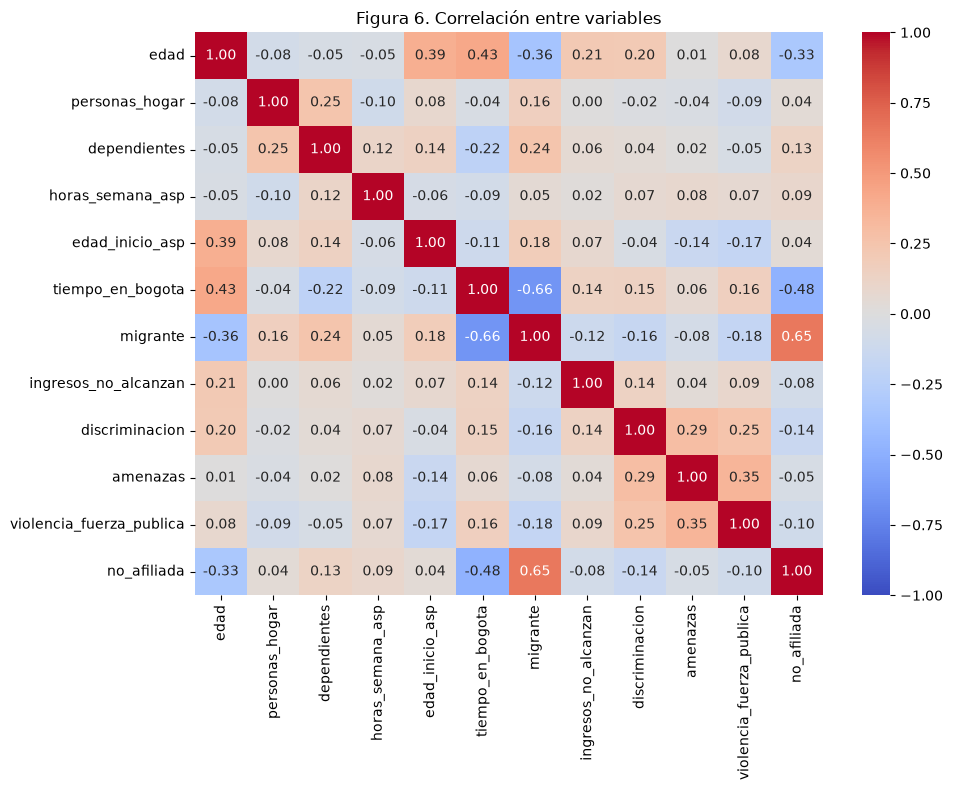

migrante                    0.65
tiempo_en_bogota           -0.48
edad                       -0.33
discriminacion             -0.14
dependientes                0.13
violencia_fuerza_publica   -0.10
horas_semana_asp            0.09
ingresos_no_alcanzan       -0.08
amenazas                   -0.05
edad_inicio_asp             0.04
personas_hogar              0.04
Name: no_afiliada, dtype: float64


In [49]:
tiempo = {"Menos de 1 año": 0, "Entre 1 y 5 años": 1, "Entre 6 y 10 años": 2, "Más de 10 años": 3}

c = pd.DataFrame({
    "edad": base["edad"],
    "personas_hogar": base["personas_hogar"],
    "dependientes": base["dependientes_economicos"],
    "horas_semana_asp": base["horas_semana_asp"],
    "edad_inicio_asp": base["edad_inicio_asp"],
    "tiempo_en_bogota": base["tiempo_viviendo_bogota"].map(tiempo),
    "migrante": (base["origen"] != "Colombia").astype(int),
    "ingresos_no_alcanzan": (base["ingresos_suficientes_gastos"] == "No").astype(int),
    "discriminacion": (base["discriminacion_general"] == "Sí").astype(int),
    "amenazas": (base["amenazas_recibidas"] == "Sí").astype(int),
    "violencia_fuerza_publica": (base["violencia_fuerza_publica"] == "Sí").astype(int),
    "no_afiliada": base["no_afiliada"],
}).dropna()          # quita 6 personas con "No sabe" en tiempo en Bogotá

corr = c.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Figura 6. Correlación entre variables")
plt.tight_layout()
plt.savefig("figuras/figura6_correlacion.png", dpi=300)
plt.show()

print(corr["no_afiliada"].drop("no_afiliada").sort_values(key=abs, ascending=False).round(2))

## Paso 9 · Tarea 23: pruebas chi-cuadrado y V de Cramér

Para cada variable de categorías hacemos la prueba chi-cuadrado, que responde si la relación con la afiliación podría ser casualidad (valor p). Con la V de Cramér medimos qué tan fuerte es la relación (0 = nada, 1 = total).

Como son casi 3.000 personas, casi todo sale «significativo», incluso relaciones muy débiles. Por eso nos fijamos en la V de Cramér: origen (0,65) y tiempo en Bogotá (0,51) pesan mucho; ingresos (0,08) y sexo (0,05) casi nada.

Limitación: la prueba junta a todas las personas, así que no separa el efecto del país de origen. Eso lo revisamos en el Paso 9B.

In [50]:
def chi_y_cramer(col):
    tabla = pd.crosstab(base[col], base["afiliado_seg_social_salud"])
    chi2, p, gl, esperados = chi2_contingency(tabla)
    n = tabla.values.sum()
    k = min(tabla.shape) - 1
    v = np.sqrt(chi2 / (n * k))
    return [col, round(chi2, 1), gl, p, round(v, 3)]

variables_prueba = ["origen", "tiempo_viviendo_bogota", "estrato", "localidad", "educacion",
                    "discriminacion_general", "autoreconocimiento_etnico", "violencia_fuerza_publica",
                    "ingresos_suficientes_gastos", "amenazas_recibidas", "sexo_nacimiento"]

resultado = pd.DataFrame([chi_y_cramer(v) for v in variables_prueba],
                         columns=["variable", "chi2", "grados_libertad", "p_valor", "V_Cramer"])
resultado = resultado.sort_values("V_Cramer", ascending=False)
resultado["p_valor"] = resultado["p_valor"].apply(lambda x: f"{x:.2e}")
resultado

,variable,chi2,grados_libertad,p_valor,V_Cramer
0,origen,1267.6,2,5.63e-276,0.651
1,tiempo_viviendo_bogota,768.5,4,5.22e-165,0.507
2,estrato,272.6,8,2.81e-54,0.302
3,localidad,182.8,18,2.68e-29,0.247
4,educacion,99.9,5,5.61e-20,0.183
5,discriminacion_general,59.5,2,1.20e-13,0.141
6,autoreconocimiento_etnico,45.8,6,3.26e-08,0.124
7,violencia_fuerza_publica,28.8,2,5.53e-07,0.098
8,ingresos_suficientes_gastos,19.0,2,7.67e-05,0.080
9,amenazas_recibidas,8.5,2,1.43e-02,0.053


## Paso 9B · Tarea 23 (extra): ¿los ingresos importan dentro de cada país?

Repetimos la prueba de ingresos contra afiliación por separado en Colombia y en Venezuela.

Sin separar, los ingresos parecen relacionados (p ≈ 0,000). Dentro de cada país la relación desaparece (Colombia p = 0,70; Venezuela p = 0,34, V casi 0). Esto confirma con una prueba lo que vimos en el Paso 7B: era el efecto del origen.

Nota: estas pruebas usan los conteos de la muestra, sin ponderar.

In [51]:
# ¿La relación ingresos-afiliación sigue existiendo dentro de cada país?
# Se hace la misma prueba chi-cuadrado, pero por separado en Colombia y en Venezuela.
sub = base[base["ingresos_suficientes_gastos"].isin(["Sí", "No"])]

def prueba_ingresos(datos, nombre):
    tabla = pd.crosstab(datos["ingresos_suficientes_gastos"], datos["afiliado_seg_social_salud"])
    chi2, p, gl, esperados = chi2_contingency(tabla, correction=False)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    return [nombre, tabla.values.sum(), round(chi2, 2), round(p, 3), round(v, 3)]

filas = [prueba_ingresos(sub, "Todas (sin separar)"),
         prueba_ingresos(sub[sub["origen"] == "Colombia"], "Solo Colombia"),
         prueba_ingresos(sub[sub["origen"] == "Venezuela"], "Solo Venezuela")]
pd.DataFrame(filas, columns=["grupo", "personas", "chi2", "p_valor", "V_Cramer"])

,grupo,personas,chi2,p_valor,V_Cramer
0,Todas (sin separar),2969,17.27,0.000,0.076
1,Solo Colombia,1697,0.14,0.704,0.009
2,Solo Venezuela,1267,0.92,0.337,0.027


## Paso 11 · Tarea 25: reproducir el clustering y perfilar cada grupo

Repetimos el clustering del equipo: variables numéricas, escalado, PCA de 8 componentes y K-Means con K = 3 (`random_state=42`). Después calculamos el perfil promedio ponderado de cada grupo.

Así conectamos el EDA con el clustering y podemos describir cómo es cada grupo. Los tamaños tienen que dar igual que en el notebook del equipo: 451, 1.380 y 1.172 personas.

Importante: la afiliación a salud **no se usó para formar los grupos**. La agregamos después, solo para describirlos. Por eso, que un grupo tenga mucha o poca afiliación es un hallazgo y no algo circular.

In [52]:
variables = ["edad", "personas_hogar", "dependientes_economicos", "autopercepcion_nivel_economico",
             "horas_semana_asp", "edad_inicio_asp", "tiempo_viviendo_bogota", "nivel_educativo",
             "tipo_vivienda", "pais_nacimiento", "autoreconocimiento_etnico", "victima_conflicto_armado",
             "ingresos_suficientes_gastos", "paga_intermediario_tercero", "discriminacion_general",
             "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]
datos = df[variables].copy()

# "No sabe/No responde" -> respuesta más frecuente de esa columna
for col in datos.columns:
    if datos[col].dtype != "int64" and datos[col].dtype != "float64":
        moda = datos[col][datos[col] != "No sabe/No responde"].mode()[0]
        datos[col] = datos[col].replace("No sabe/No responde", moda)

educacion_num = {"Ninguno": 0, "Preescolar": 0, "Básica primaria": 1, "Básica secundaria": 2, "Media": 3,
                 "Técnico": 4, "Tecnológico": 4, "Universitario": 5, "Especialización": 6, "Doctorado": 6}
vivienda_num = {"Casa": 0, "Apartamento": 0, "Otro tipo de vivienda": 0,
                "Cuarto en estructura tipo vivienda": 1, "Cuarto en hotel": 2,
                "Cuarto en el establecimiento de ASP": 2}
datos["tiempo_viviendo_bogota"] = datos["tiempo_viviendo_bogota"].map(tiempo)
datos["nivel_educativo"] = datos["nivel_educativo"].map(educacion_num)
datos["tipo_vivienda"] = datos["tipo_vivienda"].map(vivienda_num)
datos["pais_nacimiento"] = (datos["pais_nacimiento"] != "Colombia").astype(int)
datos["autoreconocimiento_etnico"] = (datos["autoreconocimiento_etnico"] != "Ninguno").astype(int)
datos["ingresos_suficientes_gastos"] = (datos["ingresos_suficientes_gastos"] == "No").astype(int)
for col in ["victima_conflicto_armado", "paga_intermediario_tercero", "discriminacion_general",
            "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]:
    datos[col] = (datos[col] == "Sí").astype(int)
datos = datos.rename(columns={"pais_nacimiento": "migrante", "autoreconocimiento_etnico": "grupo_etnico",
                              "ingresos_suficientes_gastos": "ingresos_insuficientes"})

# escalar -> PCA (8 componentes, ~66 %) -> K-Means con k = 3
escalados = StandardScaler().fit_transform(datos.values)
acumulada = np.cumsum(PCA().fit(escalados).explained_variance_ratio_)
n_comp = int(np.argmax(acumulada >= 0.65) + 1)
pca = PCA(n_components=n_comp)
componentes = pca.fit_transform(escalados)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(componentes)

df["cluster"] = kmeans.labels_
print("Componentes:", n_comp, "| Personas por cluster:", df["cluster"].value_counts().sort_index().to_dict())

# perfil de cada grupo: promedios ponderados (en 0/1 el promedio es un porcentaje)
datos["cluster"] = kmeans.labels_
datos["no_afiliada_salud"] = (df["afiliado_seg_social_salud"] == "No").astype(int)
datos["factor_expansion"] = df["factor_expansion"]
columnas = datos.columns.drop(["cluster", "factor_expansion"])
ponderado = datos[columnas].multiply(datos["factor_expansion"], axis=0)
ponderado["cluster"] = datos["cluster"]
perfiles = ponderado.groupby("cluster").sum().div(datos.groupby("cluster")["factor_expansion"].sum(), axis=0)
perfiles["porcentaje_poblacion"] = datos.groupby("cluster")["factor_expansion"].sum() / datos["factor_expansion"].sum() * 100

# ponemos nombre a cada grupo según sus rasgos (no según el número, que puede cambiar)
nombres = {}
nombres[perfiles["migrante"].idxmax()] = "Migrantes de llegada reciente"
nombres[perfiles["amenazas_recibidas"].idxmax()] = "Alta exposición a violencias"
nombres[[k for k in perfiles.index if k not in nombres][0]] = "Colombianas establecidas con precariedad económica"
df["perfil"] = df["cluster"].map(nombres)
perfiles.index = perfiles.index.map(nombres)
perfiles.T.round(2)

Componentes: 8 | Personas por cluster: {0: 451, 1: 1380, 2: 1172}


cluster,Alta exposición a violencias,Migrantes de llegada reciente,Colombianas establecidas con precariedad económica
edad,33.61,26.66,36.04
personas_hogar,2.04,2.72,2.37
dependientes_economicos,2.14,2.75,1.70
autopercepcion_nivel_economico,3.09,3.86,3.28
horas_semana_asp,53.06,48.28,43.48
edad_inicio_asp,19.06,23.32,22.58
tiempo_viviendo_bogota,2.15,0.78,2.61
nivel_educativo,2.51,2.99,2.32
tipo_vivienda,1.13,0.86,0.65
migrante,0.15,0.87,0.01


## Paso 12 · Tarea 26: visualizar los clústeres en 2D

Dibujamos a las personas sobre las dos primeras componentes del PCA, con un color por grupo.

Los grupos se traslapan un poco (el coeficiente de silhouette es bajo, cerca de 0,17). Es normal en encuestas, porque las condiciones de vida no se separan en grupos totalmente distintos.

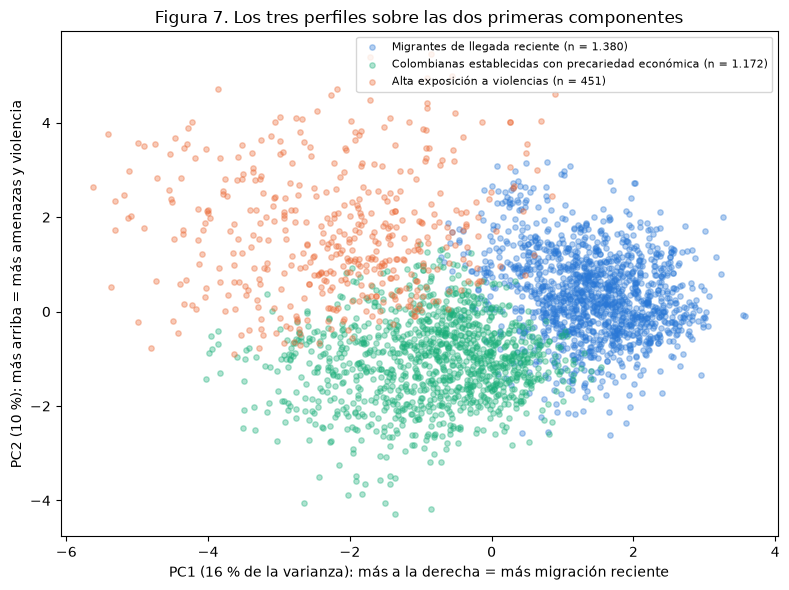

In [53]:
colores = {"Migrantes de llegada reciente": "#2a78d6",
           "Colombianas establecidas con precariedad económica": "#1baf7a",
           "Alta exposición a violencias": "#eb6834"}

plt.figure(figsize=(8, 6))
for nombre, color in colores.items():
    idx = (df["perfil"] == nombre).values
    plt.scatter(componentes[idx, 0], componentes[idx, 1], s=15, alpha=0.35, color=color,
                label=f"{nombre} (n = {idx.sum():,})".replace(",", "."))
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f} % de la varianza): más a la derecha = más migración reciente")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f} %): más arriba = más amenazas y violencia")
plt.title("Figura 7. Los tres perfiles sobre las dos primeras componentes")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figuras/figura7_clusters_pca.png", dpi=300)
plt.show()

## Paso 13 · Tarea 25: gráfica del perfil

Mostramos qué porcentaje de cada grupo no tiene afiliación a salud y qué parte de la población representa:

- Migrantes de llegada reciente (49,5 % de la población): 79 % sin afiliación.
- Colombianas establecidas con precariedad económica (37,0 %): 19 %.
- Alta exposición a violencias (13,5 %): 32 %.

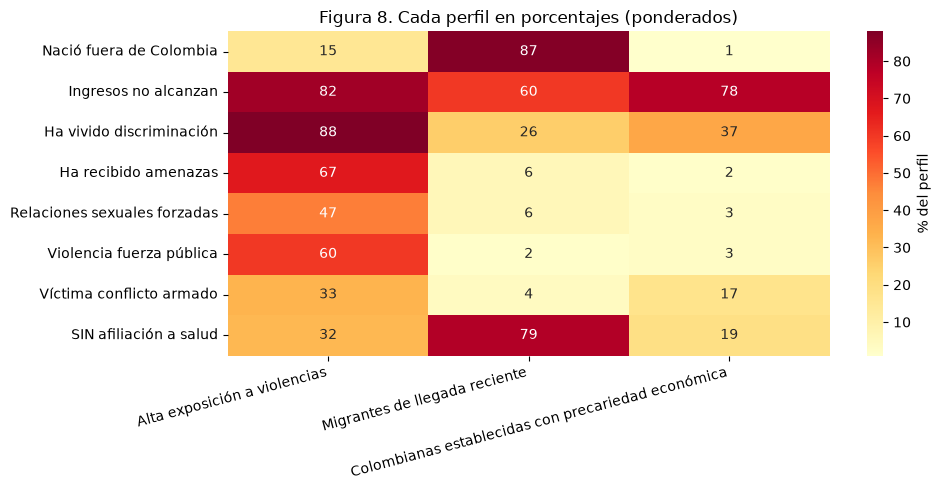

cluster
Alta exposición a violencias                          13.5
Migrantes de llegada reciente                         49.5
Colombianas establecidas con precariedad económica    37.0
Name: porcentaje_poblacion, dtype: float64


In [54]:
clave = ["migrante", "ingresos_insuficientes", "discriminacion_general", "amenazas_recibidas",
         "forzada_relaciones_sexuales", "violencia_fuerza_publica", "victima_conflicto_armado", "no_afiliada_salud"]
t = (perfiles[clave] * 100).round(0)
etiquetas = ["Nació fuera de Colombia", "Ingresos no alcanzan", "Ha vivido discriminación", "Ha recibido amenazas",
             "Relaciones sexuales forzadas", "Violencia fuerza pública", "Víctima conflicto armado", "SIN afiliación a salud"]
t.columns = etiquetas

plt.figure(figsize=(10, 5))
sns.heatmap(t.T, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% del perfil"})
plt.title("Figura 8. Cada perfil en porcentajes (ponderados)")
plt.ylabel(""); plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("figuras/figura8_perfiles.png", dpi=300)
plt.show()
print(perfiles["porcentaje_poblacion"].round(1))

## Paso 14 · Tarea 28: revisar las figuras guardadas

Listamos las figuras que se guardaron en la carpeta `figuras` (alta resolución, 300 dpi, con título y número).

Hay que revisar que sean 8 archivos y que se vean completos al abrirlos. Estas son las figuras que van al documento.

In [55]:
for f in sorted(os.listdir("figuras")):
    print(f)

figura1_edad.png
figura2_escolaridad_ingresos.png
figura3_localidad.png
figura4_afiliacion.png
figura5_cruces.png
figura6_correlacion.png
figura7_clusters_pca.png
figura8_perfiles.png


## Paso 15 · Exportar los datos para Power BI

Guardamos dos archivos CSV:

- `asp_2022_con_perfil.csv`: la base completa más el grupo (perfil) de cada persona.
- `perfiles_ponderados.csv`: la tabla resumen de los 3 perfiles.

Power BI lee archivos CSV. Los guardamos en UTF-8 para que «Mártires» y las demás tildes no salgan mal.

In [56]:
# 1) todas las personas con su perfil asignado y la variable de afiliación
salida = df.copy()
salida["no_afiliada"] = (salida["afiliado_seg_social_salud"] == "No").astype(int)
salida.to_csv("asp_2022_con_perfil.csv", index=False, encoding="utf-8-sig")

# 2) tabla resumen de los perfiles
perfiles.round(3).to_csv("perfiles_ponderados.csv", encoding="utf-8-sig")

print("Archivos creados:", salida.shape, perfiles.shape)

Archivos creados: (3003, 54) (3, 20)


## Paso 16 · Tarea 27: hallazgos clave del EDA

1. **El origen y el tiempo en Bogotá explican la falta de afiliación.** Sin afiliación: 21,1 % en nacidas en Colombia contra 85,9 % en nacidas en Venezuela; 74 % con menos de 5 años en Bogotá contra 19 % con más de 10. Son las dos relaciones más fuertes (V de Cramér 0,65 y 0,51).
2. **Los ingresos no tienen relación propia con la afiliación.** Sin separar por país parece que sí (y hasta al revés), pero dentro de Colombia (p = 0,70) y de Venezuela (p = 0,34) la relación desaparece. Era el efecto del origen.
3. **La población es joven y con poca escolaridad.** La mediana de edad es 29 años, el 80,5 % llegó como máximo a educación media y el 68,9 % dice que sus ingresos no alcanzan.
4. **La afiliación está casi 50/50** (No 50,6 %, Sí 49,0 %), así que no hay desbalance que corregir.
5. **La población se concentra en pocas localidades:** Los Mártires reúne el 37,1 % y Kennedy el 16,8 %.
6. **Hay tres perfiles.** Migrantes de llegada reciente (49,5 %, 79 % sin afiliación), colombianas establecidas con precariedad económica (37,0 %, 19 %) y alta exposición a violencias (13,5 %, 32 %).
7. **Violencia y falta de afiliación son cosas distintas.** El grupo con más violencia no es el de peor afiliación; la falta de afiliación se concentra en el grupo migrante.

**Límites:** el coeficiente de silhouette es bajo (≈ 0,17), así que los perfiles se traslapan; las asociaciones no prueban causa; y los datos son solo de Bogotá 2022.